# Poplar-Studio: skeleton-guided 3D poplar seedling reconstruction — four-method lamina reconstruction demo

Reproduction of: **Z. Wang et al., "Poplar-Studio: skeleton-guided reconstruction of editable 3D poplar seedling models from multi-view point clouds", *Computers and Electronics in Agriculture* 256:112454 (2026)**, DOI: [10.1016/j.compag.2026.112454](https://doi.org/10.1016/j.compag.2026.112454)

Author code: `wanghanruibaba/Poplar-Studio` @ commit `4aabe9f25c05` (checked inside this notebook).

**Scope (partial demonstration).** The paper converts multi-view point clouds of poplar seedlings into editable organ-level 3D models. The paper's core leaf-area validation compares four lamina-reconstruction methods — the proposed **PCA boundary-constrained meshing** plus **adaptive Poisson**, **fixed Poisson**, and **ball pivoting** baselines — against independently measured leaf areas (paper-level: R² = 0.943, relative RMSE 10.3% over a 240-leaf benchmark). This notebook re-runs **all four methods on two embedded benchmark leaves** (selected at runtime from the author's `leaf_manifest.csv`: benchmark leaves stored in sample folder `raw/0001`) using the author's original, unmodified code, and compares the reconstructed areas against the author-frozen benchmark table (`benchmark/sampled_four_method_leaf_areas.csv`) and the released benchmark meshes.

**Not covered:** SfM-MVS image acquisition, PointNet++ leaf/stem segmentation, skeleton graph construction, stem validation, and the full 240-leaf benchmark are out of scope. A two-leaf run is a plausibility check, not verification of published dataset-level accuracy.

**実行範囲(日本語):** 埋め込みサンプル(raw/0001)から著者マニフェストにより選択したベンチマーク葉2枚に対し、著者コードをそのまま用いてPCA法+3つのベースライン法の葉面積再構成を実行し、著者公開のベンチマーク表・メッシュと面積を比較します。SfM・点群セグメンテーション・骨格解析・240葉ベンチマーク全体は対象外です。

## Runtime: CPU only

The author's reconstruction code uses only NumPy, SciPy, and Open3D **on CPU** (no torch, no CUDA operations anywhere in the pinned repository). Poisson reconstruction depth ≤ 11 on a single leaf cloud (a few thousand points) takes seconds on CPU, so **no GPU is needed**: select **Runtime → Change runtime type → CPU** (the default free runtime).

Expected duration: ~5 minutes total (≈2 min Open3D install + ≈1 min download + ≈1–2 min reconstruction). Downloads: ≈12 MB.

**実行環境(日本語):** 著者コードはNumPy/SciPy/Open3DのCPU実装のみで、GPUは不要です。ランタイム種別はCPUのままで実行してください。所要時間は全体で約5分、ダウンロード約12MBです。

### Check the environment

We print the Python, NumPy and SciPy versions and the CPU resources of the allocated runtime, so the recorded result is tied to actual observed hardware. No GPU is requested or used.

**実行内容:** 割り当てられたCPUランタイムのPython/NumPy/SciPyバージョンとCPU資源を確認します。GPUは使用しません。

In [ ]:
import platform, os, multiprocessing
import numpy as np, scipy
print("Python:", platform.python_version())
print("numpy:", np.__version__, "| scipy:", scipy.__version__)
print("CPU cores:", multiprocessing.cpu_count())
mem_gb = None
try:
    with open("/proc/meminfo") as f:
        for line in f:
            if line.startswith("MemTotal"):
                mem_gb = int(line.split()[1]) / 1024**2
                print(f"Total RAM: {mem_gb:.1f} GiB")
                break
except OSError as e:
    print("meminfo unavailable:", e)

Python: 3.13.16
numpy: 2.1.3 | scipy: 1.16.3
CPU cores: 2
Total RAM: 12.7 GiB


### Install Open3D

`pca_reconstruct.py` (the proposed PCA method) needs only NumPy/SciPy, but `baseline_core.py` imports **Open3D** for Poisson reconstruction, ball pivoting, mesh cleanup, and density cropping. We pin the newest Open3D release providing manylinux wheels for the Colab runtime's Python (3.13): `open3d==0.20.0`. The import is asserted after install so a silent wheel failure cannot pass unnoticed.

**実行内容:** ベースライン法(open3d利用)のため、ColabのPython(3.13)に対応するOpen3D 0.20.0をインストールし、インポートを確認します。

In [ ]:
%pip install -q open3d==0.20.0
import open3d as o3d
print("open3d:", o3d.__version__)

open3d: 0.20.0


### Download the pinned author repository (partial clone, exact commit)

Inside this Colab VM (never on the authoring host), we make a **blobless partial clone** and check out the exact verified commit `4aabe9f25c0550b885c47cf4bb8d94f07c559100` in detached HEAD, with a sparse checkout limited to what this demo needs: the four author code files, `leaf_manifest.csv`, the embedded sample-leaf folder `raw/0001` (21 leaves, each with its raw point cloud `.txt` and the author's PCA mesh), and the `benchmark/` folder (archived per-method meshes + reference CSVs). The checkout is asserted to match the pinned commit.

**実行内容:** 著者リポジトリを部分クローンし、検証済みコミット4aabe9f25c05をスパースチェックアウトします。

In [ ]:
import subprocess, os
REPO = "/content/Poplar-Studio"
COMMIT = "4aabe9f25c0550b885c47cf4bb8d94f07c559100"
URL = "https://github.com/wanghanruibaba/Poplar-Studio.git"
FILES = ["leaf_manifest.csv", "pca_reconstruct.py", "baseline_core.py",
         "reconstruct.py", "recalculate_areas.py", "raw/0001", "raw/0002", "benchmark"]

def sh(*args, **kw):
    return subprocess.run(args, check=True, capture_output=True, text=True, **kw)

if not os.path.isdir(os.path.join(REPO, ".git")):
    sh("git", "init", "-q", REPO)
    sh("git", "-C", REPO, "remote", "add", "origin", URL)
    sh("git", "-C", REPO, "config", "extensions.partialClone", "origin")
    sh("git", "-C", REPO, "sparse-checkout", "init", "--no-cone")
    sh("git", "-C", REPO, "sparse-checkout", "set", *FILES)
sh("git", "-C", REPO, "fetch", "--depth=1", "--filter=blob:none", "origin", COMMIT)
sh("git", "-C", REPO, "checkout", "-q", "FETCH_HEAD")
head = sh("git", "-C", REPO, "rev-parse", "HEAD").stdout.strip()
assert head == COMMIT, f"checkout {head} != pinned {COMMIT}"
print("Checked out pinned commit:", head)

Checked out pinned commit: 4aabe9f25c0550b885c47cf4bb8d94f07c559100


### Verify the retrieved files

We list the checked-out sample data and code with byte sizes. The demo leaves themselves are verified right after the manifest is loaded (their exact filenames come from the author's manifest, not from assumptions).

**実行内容:** 取得したサンプル点群・コード・ベンチマークファイルの実在とサイズを確認します。デモ葉の実在確認はマニフェスト読込後に行います。

In [ ]:
import os
REPO = "/content/Poplar-Studio"
for name in ["leaf_manifest.csv", "pca_reconstruct.py", "baseline_core.py",
             "recalculate_areas.py", "reconstruct.py"]:
    p = os.path.join(REPO, name)
    assert os.path.isfile(p), p
    print(f"{name}: {os.path.getsize(p):,} bytes")
for d in ["raw/0001", "benchmark"]:
    paths = []
    for root, _, files in os.walk(os.path.join(REPO, d)):
        paths += [os.path.join(root, f) for f in files]
    print(f"{d}: {len(paths)} files, {sum(os.path.getsize(p) for p in paths):,} bytes")

leaf_manifest.csv: 82,992 bytes
pca_reconstruct.py: 35,740 bytes
baseline_core.py: 27,661 bytes
recalculate_areas.py: 2,795 bytes
reconstruct.py: 3,328 bytes
raw/0001: 42 files, 6,943,229 bytes
benchmark: 10 files, 4,680,514 bytes


### Load the frozen manifest and the benchmark area table, then select the two demo leaves

`leaf_manifest.csv` maps each 4-digit leaf ID to genotype, physical `scale_factor` (point units → cm), point-cloud path, author PCA-mesh path, benchmark flag, and the paper's PCA `pca_area_cm2`. `benchmark/sampled_four_method_leaf_areas.csv` holds the author-frozen four-method areas (`<method>_area_cm2`) plus the independent `measured_area_cm2` reference. Leaf IDs are read **as strings** (pandas would otherwise strip the leading zeros). The manifest's path columns use the author's local `data/`-prefixed layout while this repository stores the example leaves at its root, so paths are resolved by stripping an optional leading `data/`. We select **one benchmark leaf from sample folder `raw/0001` and one from `raw/0002`** (the two folders embedded in this repository; each storage folder contains exactly six benchmark leaves per the author's `validate_release.py`) and assert their input clouds and author PCA meshes exist on disk.

**実行内容:** 葉マニフェスト(遺伝型・スケール係数・PCA面積)とベンチマーク面積表を読み込み、raw/0001とraw/0002から各1枚のベンチマーク葉を選択し、実在を確認します。

In [ ]:
import pandas as pd
REPO = "/content/Poplar-Studio"
STR_COLS = ["leaf", "genotype", "storage_folder"]
manifest = pd.read_csv(os.path.join(REPO, "leaf_manifest.csv"), encoding="utf-8-sig",
                       dtype={c: str for c in STR_COLS})
benchmark = pd.read_csv(os.path.join(REPO, "benchmark", "sampled_four_method_leaf_areas.csv"),
                        encoding="utf-8-sig", dtype={c: str for c in STR_COLS})
print("manifest columns:", list(manifest.columns))
print("manifest rows:", len(manifest))
print("benchmark columns:", list(benchmark.columns))
print("benchmark rows:", len(benchmark))

def repo_path(rel):
    # manifest paths use the author's local 'data/...' layout; the repo root stores them directly
    rel = rel[len("data/"):] if rel.startswith("data/") else rel
    return os.path.join(REPO, rel)

is_bench = manifest["in_benchmark"].astype(str) == "True"
demo_leaves = (sorted(manifest.loc[is_bench & (manifest["storage_folder"] == "0001"), "leaf"])[:1]
               + sorted(manifest.loc[is_bench & (manifest["storage_folder"] == "0002"), "leaf"])[:1])
assert len(demo_leaves) == 2, demo_leaves
LEAF_ROW = {r["leaf"]: r for _, r in manifest[manifest["leaf"].isin(demo_leaves)].iterrows()}
for leaf in demo_leaves:
    for k in ("txt_path", "pca_obj_path"):
        p = repo_path(LEAF_ROW[leaf][k])
        assert os.path.isfile(p), (leaf, k, p)
print("\nDemo leaves (first benchmark leaf in each embedded sample folder):", demo_leaves)
print("\n--- manifest rows for demo leaves ---")
print(manifest[manifest["leaf"].isin(demo_leaves)].to_string(index=False))
print("\n--- benchmark rows for demo leaves ---")
print(benchmark[benchmark["leaf"].isin(demo_leaves)].to_string(index=False))

manifest columns: ['leaf', 'genotype', 'scale_factor', 'txt_path', 'pca_obj_path', 'in_benchmark', 'storage_folder', 'pca_area_cm2']
manifest rows: 839
benchmark columns: ['genotype', 'leaf', 'scale_factor', 'txt_path', 'pca_obj_path', 'pca_area_raw', 'pca_area_cm2', 'adaptive_poisson_success', 'adaptive_poisson_area_raw', 'adaptive_poisson_area_cm2', 'adaptive_poisson_seconds', 'fixed_poisson_success', 'fixed_poisson_area_raw', 'fixed_poisson_area_cm2', 'fixed_poisson_seconds', 'ball_pivoting_success', 'ball_pivoting_area_raw', 'ball_pivoting_area_cm2', 'ball_pivoting_seconds', 'pca_threshold_cm2', 'pca_threshold_pass', 'all_four_meshes_available', 'measured_area_cm2', 'storage_folder']
benchmark rows: 240

Demo leaves (first benchmark leaf in each embedded sample folder): ['0043', '0010']

--- manifest rows for demo leaves ---
leaf genotype  scale_factor               txt_path                    pca_obj_path  in_benchmark storage_folder  pca_area_cm2
0010       01         14.22 data/

### Preview the sample input and the author's PCA reconstruction (first demo leaf)

Before any reconstruction we visualize the actual data: left, the raw per-leaf point cloud (XY view, colored by height); right, the vertex set of the author's released PCA reconstruction for the same leaf. This is the author-provided reference reconstruction shipped with the sample — not our result.

**実行内容:** 1枚目のデモ葉の生点群(XY投影、高さ着色)と、著者公開のPCA再構成メッシュの頂点を並べて表示します。右は著者提供の参照出力であり本ノートブックの結果ではありません。

leaf 0043: 2604 input points | author PCA mesh: 2600 vertices


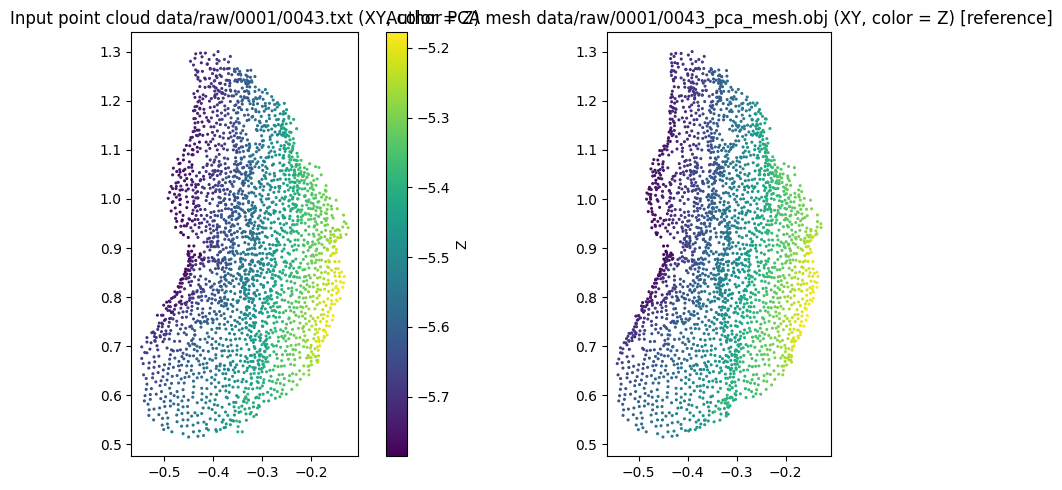

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
REPO = "/content/Poplar-Studio"

def load_xyz(path):
    try:
        d = np.loadtxt(path)
    except ValueError:
        d = np.loadtxt(path, delimiter=",")
    return d[:, :3][np.all(np.isfinite(d[:, :3]), axis=1)]

def load_obj_vertices(path):
    vs = []
    with open(path) as f:
        for line in f:
            if line.startswith("v "):
                vs.append([float(x) for x in line.split()[1:4]])
    return np.asarray(vs)

leaf = demo_leaves[0]
pts = load_xyz(repo_path(LEAF_ROW[leaf]["txt_path"]))
mesh_v = load_obj_vertices(repo_path(LEAF_ROW[leaf]["pca_obj_path"]))
print(f"leaf {leaf}: {len(pts)} input points | author PCA mesh: {len(mesh_v)} vertices")

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
s1 = axes[0].scatter(pts[:, 0], pts[:, 1], c=pts[:, 2], s=1.5, cmap="viridis")
axes[0].set_title(f"Input point cloud {LEAF_ROW[leaf]['txt_path']} (XY, color = Z)")
axes[0].set_aspect("equal"); fig.colorbar(s1, ax=axes[0], label="Z")
axes[1].scatter(mesh_v[:, 0], mesh_v[:, 1], c=mesh_v[:, 2], s=1.5, cmap="viridis")
axes[1].set_title(f"Author PCA mesh {LEAF_ROW[leaf]['pca_obj_path']} (XY, color = Z) [reference]")
axes[1].set_aspect("equal")
plt.tight_layout(); plt.savefig("/content/poplar_preview_input.png", dpi=150); plt.show()

### Run the proposed PCA lamina reconstruction (both demo leaves)

We call the author's `pca_reconstruct.process_file` with the paper's frozen defaults (`ReconstructionConfig()`: min 30 points, ≤5000 vertices, alpha factor 2.5, MLS height smoothing k=18, blend 0.65 — identical to the defaults used by the author's frozen-cohort driver `reconstruct.py`). It writes `<leaf>_pca_mesh.obj` (open single-layer surface) plus PLY/JSON to `/content/runs/reconstruction/pca/`, and reports mesh size, boundary loops, and internal holes.

**実行内容:** 著者の`process_file`を既定パラメータのまま2葉に実行し、PCA法の開放メッシュを生成します。

In [ ]:
import sys, time
sys.path.insert(0, REPO)
from pathlib import Path
import pca_reconstruct

out_dir = Path("/content/runs/reconstruction/pca"); out_dir.mkdir(parents=True, exist_ok=True)
pca_records = {}
for leaf in demo_leaves:
    t0 = time.perf_counter()
    rec = pca_reconstruct.process_file(Path(repo_path(LEAF_ROW[leaf]["txt_path"])),
                                       out_dir, pca_reconstruct.ReconstructionConfig())
    assert rec.get("success"), rec
    rec["seconds"] = time.perf_counter() - t0
    pca_records[leaf] = rec
    print(f"leaf {leaf}: {rec['mesh_vertices']} vertices, {rec['mesh_triangles']} triangles, "
          f"internal_holes={rec['internal_holes']}, {rec['seconds']:.2f} s")

[OK] 0043.txt: 2604 points -> 2600 vertices, 5058 triangles, internal_holes=0, 0.380 s
leaf 0043: 2600 vertices, 5058 triangles, internal_holes=0, 0.42 s


[OK] 0010.txt: 3087 points -> 3082 vertices, 6011 triangles, internal_holes=0, 0.433 s
leaf 0010: 3082 vertices, 6011 triangles, internal_holes=0, 0.48 s


### Run the three baseline reconstructions (adaptive Poisson, fixed Poisson, ball pivoting)

We call the author's `baseline_core.process_one(path, out_dir, method, 'reduced')` — the same entry point and `"reduced"` search budget used by the author's `reconstruct.py`. Adaptive Poisson searches a small candidate set (target-point multipliers 0.8/1.0/1.2, ≤2 refinement iterations) seeded with `RNG_SEED = 20240101`; fixed Poisson uses the frozen constants (3000 target points, depth 9); ball pivoting uses radii = median spacing × {1, 2, 4}. Meshes are written as `<leaf>_<method>.obj`. We also call the author's `_init_worker()` to match the serial single-worker execution of the frozen run.

**実行内容:** 著者の`process_one`を`reduced`予算で3ベースライン×2葉に実行します(シード20240101)。

In [ ]:
import baseline_core

baseline_core._init_worker()
BASE_OUT = {}
for method in ["adaptive_poisson", "fixed_poisson", "ball_pivoting"]:
    out_dir = Path(f"/content/runs/reconstruction/{method}"); out_dir.mkdir(parents=True, exist_ok=True)
    for leaf in demo_leaves:
        t0 = time.perf_counter()
        rec = baseline_core.process_one(repo_path(LEAF_ROW[leaf]["txt_path"]),
                                        str(out_dir), method, "reduced")
        assert rec.get("success"), rec
        rec["wall_seconds"] = time.perf_counter() - t0
        BASE_OUT[(leaf, method)] = rec
        print(f"leaf {leaf} {method}: {rec['mesh_vertices']} verts, "
              f"{rec['mesh_triangles']} tris, area={rec['area']:.3f}, {rec['wall_seconds']:.1f} s")

leaf 0043 adaptive_poisson: 4280 verts, 8301 tris, area=0.424, 39.2 s


leaf 0010 adaptive_poisson: 5768 verts, 11139 tris, area=0.298, 18.8 s


leaf 0043 fixed_poisson: 6152 verts, 11939 tris, area=0.375, 1.0 s


leaf 0010 fixed_poisson: 6528 verts, 12619 tris, area=0.290, 1.0 s
leaf 0043 ball_pivoting: 2448 verts, 3961 tris, area=0.419, 0.1 s


leaf 0010 ball_pivoting: 2923 verts, 5135 tris, area=0.330, 0.1 s


### Compare reconstructed areas with the author-frozen benchmark

Two comparisons, both using the author's exact area routine (`recalculate_areas.surface_area`, triangle cross-product sum) and cm² conversion (`raw area × scale_factor²`):

1. **Area-pipeline check** — this repository ships released benchmark meshes only for leaves `0001` and `0002` (per method). We recompute their areas exactly like the author's `recalculate_areas.main` and print the maximum absolute difference against the frozen table's `<method>_area_cm2`; it must be ≈ 0 for our area pipeline to be identical to the author's.
2. **Fresh reconstruction vs frozen values** — for the two demo leaves we compare our four fresh reconstruction areas with the frozen `<method>_area_cm2` and the independent `measured_area_cm2` reference.

**実行内容:** (1) 公開ベンチマークメッシュ(葉0001/0002)の面積を著者のルーチンで再計算し凍結表と一致することを確認します。(2) 2つのデモ葉の新規再構成面積を凍結値・独立実測値と比較します。

In [ ]:
from recalculate_areas import surface_area
import pandas as pd

METHODS = ["pca", "adaptive_poisson", "fixed_poisson", "ball_pivoting"]
SUFFIX = {"pca": "_pca_mesh.obj", "adaptive_poisson": "_adaptive_poisson.obj",
          "fixed_poisson": "_fixed_poisson.obj", "ball_pivoting": "_ball_pivoting.obj"}

# --- 1) area-pipeline check on the released benchmark meshes (leaves 0001/0002) ---
max_frozen_diff = 0.0
for leaf in ["0001", "0002"]:
    brow = benchmark[benchmark["leaf"] == leaf].iloc[0]
    scale2 = float(brow["scale_factor"]) ** 2
    for method in METHODS:
        released = surface_area(f"{REPO}/benchmark/{method}/{leaf}{SUFFIX[method]}") * scale2
        archived = float(brow[f"{method}_area_cm2"])
        max_frozen_diff = max(max_frozen_diff, abs(released - archived))
print(f"Max |released benchmark mesh area - archived table area| = {max_frozen_diff:.6g} cm2"
      "  (area-pipeline check, author recalculate_areas route; must be ~0)")

# --- 2) fresh four-method reconstruction of the demo leaves vs frozen/measured values ---
scale = {leaf: float(LEAF_ROW[leaf]["scale_factor"]) for leaf in demo_leaves}
rows = []
for method in METHODS:
    for leaf in demo_leaves:
        fresh = surface_area(f"/content/runs/reconstruction/{method}/{leaf}{SUFFIX[method]}") \
                * scale[leaf] ** 2
        brow = benchmark[benchmark["leaf"] == leaf].iloc[0]
        archived = float(brow[f"{method}_area_cm2"])
        rows.append({"leaf": leaf, "method": method, "scale_factor": scale[leaf],
                     "fresh_area_cm2": round(fresh, 4),
                     "archived_area_cm2": archived,
                     "measured_area_cm2": float(brow["measured_area_cm2"]),
                     "fresh_vs_archived_pct": round(100 * (fresh - archived) / archived, 3),
                     "fresh_vs_measured_pct": round(100 * (fresh - brow["measured_area_cm2"])
                                                    / brow["measured_area_cm2"], 3)})
results = pd.DataFrame(rows)
display(results)

Max |released benchmark mesh area - archived table area| = 0.000275158 cm2  (area-pipeline check, author recalculate_areas route; must be ~0)


,leaf,method,scale_factor,fresh_area_cm2,archived_area_cm2,measured_area_cm2,fresh_vs_archived_pct,fresh_vs_measured_pct
0,0043,pca,12.65,69.7438,69.743845,70.547171,-0.000,-1.139
1,0010,pca,14.22,69.8004,69.800407,69.514664,0.000,0.411
2,0043,adaptive_poisson,12.65,67.8311,70.709184,70.547171,-4.070,-3.850
3,0010,adaptive_poisson,14.22,60.2620,60.263175,69.514664,-0.002,-13.310
4,0043,fixed_poisson,12.65,60.0426,60.042209,70.547171,0.001,-14.890
5,0010,fixed_poisson,14.22,58.6464,58.646448,69.514664,-0.000,-15.634
6,0043,ball_pivoting,12.65,67.0733,67.073510,70.547171,-0.000,-4.924
7,0010,ball_pivoting,14.22,66.7157,66.715618,69.514664,0.000,-4.026


### Visualize the four-method area comparison

For each demo leaf we plot the four methods' **fresh areas from this notebook's run** against the **author-frozen archived areas**, with the independent measured reference as a dashed line. This graph is generated here from the actual executed results (an additional visualization created for this notebook, not a figure reproduced from the paper).

**実行内容:** 本ノートブックの実行結果と著者凍結値・独立実測値を棒グラフで比較します(本ノートブック独自の追加可視化であり、論文図の再現ではありません)。

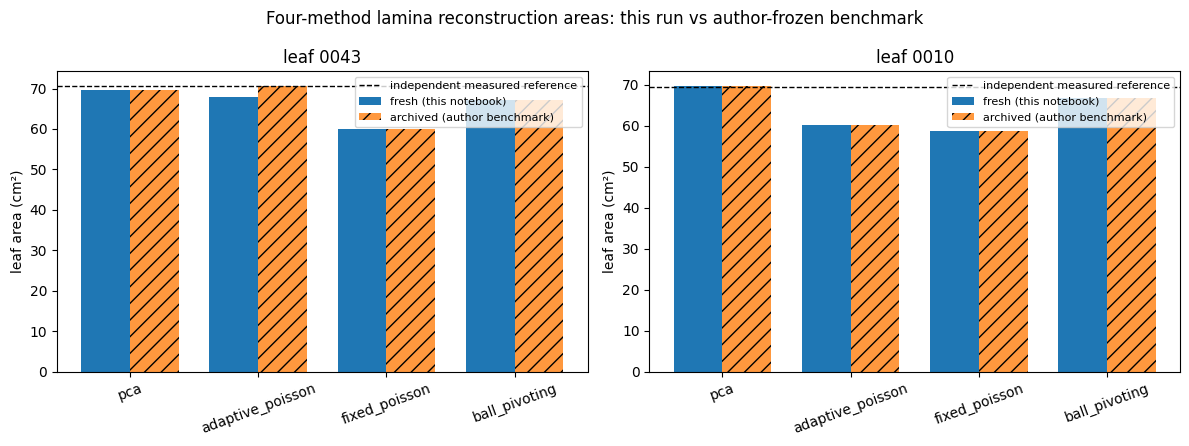

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)
x = np.arange(len(METHODS)); w = 0.38
for ax, leaf in zip(axes, demo_leaves):
    sub = results[results["leaf"] == leaf].set_index("method").loc[METHODS]
    ax.bar(x - w / 2, sub["fresh_area_cm2"], w, label="fresh (this notebook)")
    ax.bar(x + w / 2, sub["archived_area_cm2"], w, label="archived (author benchmark)",
           hatch="//", alpha=0.8)
    ax.axhline(sub["measured_area_cm2"].iloc[0], ls="--", c="k", lw=1,
               label="independent measured reference")
    ax.set_xticks(x, METHODS, rotation=20)
    ax.set_ylabel("leaf area (cm²)")
    ax.set_title(f"leaf {leaf}")
    ax.legend(fontsize=8)
plt.suptitle("Four-method lamina reconstruction areas: this run vs author-frozen benchmark")
plt.tight_layout(); plt.savefig("/content/poplar_area_comparison.png", dpi=150); plt.show()

### Interpretation and limitations

- **What is verified here:** the author's original code (pinned commit) runs end-to-end in Colab on the embedded sample leaves; our recomputed areas of the *released* benchmark meshes match the frozen table, and our *fresh* reconstructions can be compared with those frozen values per method.
- **What is not verified:** the paper's dataset-level statistics (R² = 0.943, relative RMSE 10.3% over 240 leaves), the SfM/segmentation/skeleton stages, and any claim about the full pipeline. Two leaves is a plausibility demonstration.
- Numerical variation: Poisson and ball-pivoting contain seeded resampling (`RNG_SEED = 20240101`); small area differences vs the frozen values are expected across platforms/Open3D versions.

**結果の解釈(日本語):** 本ノートブックは著者コードがColab上で完走し、公開ベンチマークメッシュの面積が凍結表と一致すること、また新規再構成の面積を凍結値と比較できることを示します。240葉の統計量やSfM・セグメンテーション・骨段階は検証対象外です。Poisson法・BPA法はシード付きリサンプリングを含むため、環境差によるわずかな面積差は想定内です。

### Export the comparison table

We save the executed comparison table as CSV in the Colab VM (`/content/poplar_area_results.csv`) so the learner can download it.

**実行内容:** 比較表をCSVとして保存します。

In [ ]:
results.to_csv("/content/poplar_area_results.csv", index=False, encoding="utf-8-sig")
print("saved /content/poplar_area_results.csv")
print(results.to_string(index=False))

saved /content/poplar_area_results.csv
leaf           method  scale_factor  fresh_area_cm2  archived_area_cm2  measured_area_cm2  fresh_vs_archived_pct  fresh_vs_measured_pct
0043              pca         12.65         69.7438          69.743845          70.547171                 -0.000                 -1.139
0010              pca         14.22         69.8004          69.800407          69.514664                  0.000                  0.411
0043 adaptive_poisson         12.65         67.8311          70.709184          70.547171                 -4.070                 -3.850
0010 adaptive_poisson         14.22         60.2620          60.263175          69.514664                 -0.002                -13.310
0043    fixed_poisson         12.65         60.0426          60.042209          70.547171                  0.001                -14.890
0010    fixed_poisson         14.22         58.6464          58.646448          69.514664                 -0.000                -15.634
0043    b

## References

- Paper: *Computers and Electronics in Agriculture* 256:112454 (2026), DOI 10.1016/j.compag.2026.112454 (published ScienceDirect HTML, online 2026-09-22, CC BY-NC-ND).
- Code: https://github.com/wanghanruibaba/Poplar-Studio @ commit `4aabe9f25c0550b885c47cf4bb8d94f07c559100` — `pca_reconstruct.py` (PCA method), `baseline_core.py` (baselines), `recalculate_areas.py` (area routine), `reconstruct.py` (frozen-cohort driver, mirrored here), `validate_release.py` (data layout invariants: 839 leaves, 40 storage folders, 6 benchmark leaves per folder).
- Data: embedded example leaves in `raw/0001` + `raw/0002` (inputs + author PCA meshes) and `benchmark/` released meshes (leaves 0001/0002) + `sampled_four_method_leaf_areas.csv` from the same pinned commit; demo leaves are selected from the author manifest at runtime.
- PhenoPaper investigation `p-cd2cf156846799a5a246f2cd226e37c7-20261019T110852Z-645682` was used as research guidance; all scientific steps above were verified against the pinned author code directly.

**参考(日本語):** 上記の論文・コミット固定の著者コード・埋め込みサンプルデータのみに基づいています。